# Exploratory Data Analysis

Creating the rates and exploring data with charts

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/accidents_by_municipality_year.csv",
                 dtype={"municipality_code": str, "region_code": str},
                 keep_default_na=False)
df.isnull().sum()                

municipality_code    0
year                 0
accidents            0
deaths               0
injured              0
municipality         0
province             0
region_code          0
geo_area_code        0
province_capital     0
population           0
area_km2             0
region               0
geographic_area      0
dtype: int64

I want to know which period I should analyse.

In [22]:
df_year = df.groupby("year")[["accidents", "deaths", "injured"]].sum()
print(df_year)

      accidents  deaths  injured
year                            
2001     254474    6808   360998
2002     256915    6733   366052
2003     244303    6332   345189
2004     235979    5848   332876
2005     232372    5631   324376
2006     229576    5406   321062
2007     222795    4927   314205
2008     211432    4546   299818
2009     207545    4040   295541
2010     210480    4026   300859
2011     203230    3784   288301
2012     185810    3647   263145
2013     179345    3305   254705
2014     175268    3321   248348
2015     172746    3347   244236
2016     174096    3216   246481
2017     174375    3358   245894
2018     172208    3318   242420
2019     172099    3173   241245
2020     118269    2395   159213
2021     151838    2873   204678
2022     165852    3158   223430
2023     166489    3038   224586
2024     173364    3030   233853


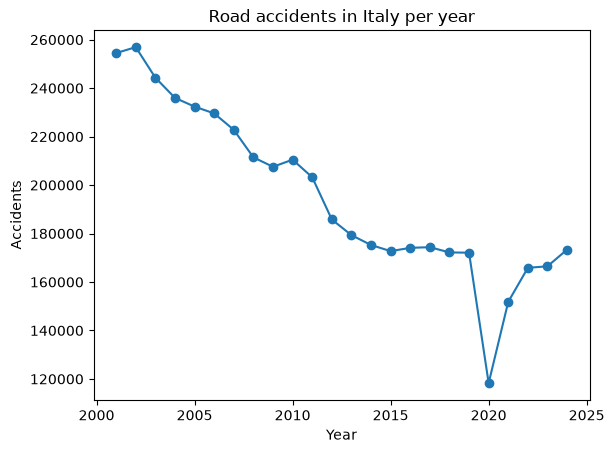

In [23]:
plt.plot(df_year.index, df_year["accidents"], marker="o")
plt.title("Road accidents in Italy per year")
plt.xlabel("Year")
plt.ylabel("Accidents")
plt.show()

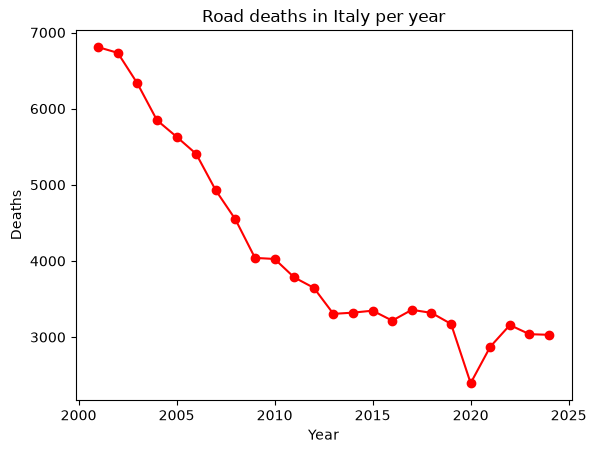

In [24]:
plt.plot(df_year.index, df_year["deaths"], marker="o", color="red")
plt.title("Road deaths in Italy per year")
plt.xlabel("Year")
plt.ylabel("Deaths")
plt.show()

I notice that accidents and deaths decreased from 2001 to 2019. I see that 2020 is an outlier, but I think because of the COVID lockdown.
I decided to use 2022, 2023 and 2024 because they are stable and most recent.

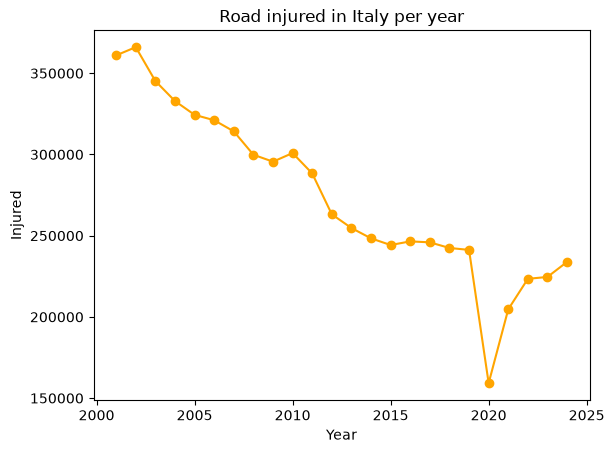

In [25]:
plt.plot(df_year.index, df_year["injured"], marker="o", color="orange")
plt.title("Road injured in Italy per year")
plt.xlabel("Year")
plt.ylabel("Injured")
plt.show()


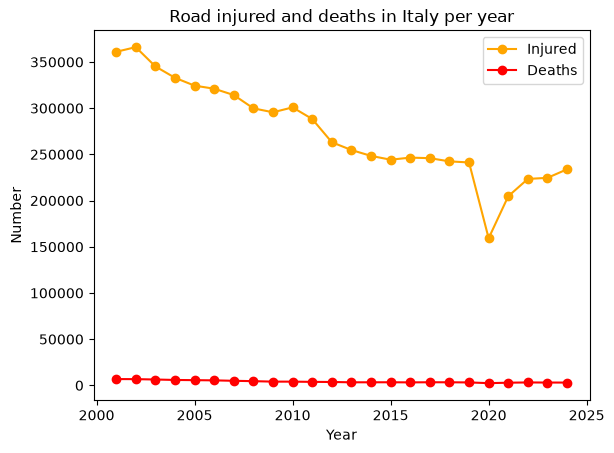

In [26]:
plt.plot(df_year.index, df_year["injured"], label="Injured", marker="o", color="orange")
plt.plot(df_year.index, df_year["deaths"], label="Deaths", marker="o", color="red")
plt.title("Road injured and deaths in Italy per year")
plt.xlabel("Year")
plt.ylabel("Number")
plt.legend()
plt.show()

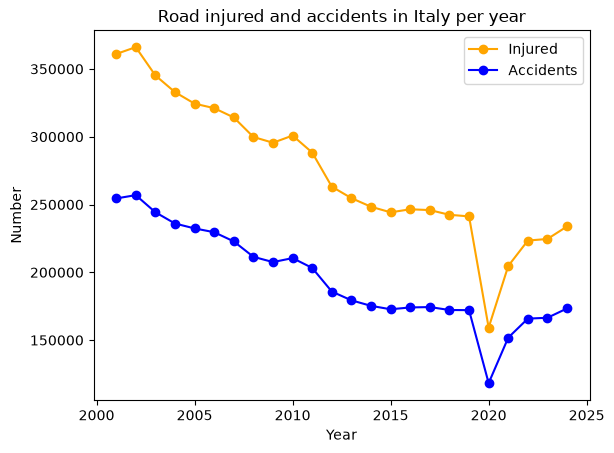

In [27]:
plt.plot(df_year.index, df_year["injured"], label="Injured", marker="o", color="orange")
plt.plot(df_year.index, df_year["accidents"], label="Accidents", marker="o", color="blue")
plt.title("Road injured and accidents in Italy per year")
plt.xlabel("Year")
plt.ylabel("Number")
plt.legend()
plt.show()

#One row per municipality (average 2022-2024)

Now I want to count how many rows each municipality has, to check if some years are missing. I keep only the years 2022, 2023, 2024. Each row is one municipality in 1 year, so every municipality should have 3 rows.

In [28]:
df_last_yrs = df[df["year"] >= 2022]
df_last_yrs.groupby("municipality_code") ["year"].count().value_counts()

year
3    6335
2    1555
1       6
Name: count, dtype: int64

I see that 6.335 municipalities have 3 rows, so data are complete;
1.555 have 2 rows because there isn't 2024 (I found in the cleaning notebook that it means 0 accidents);
6 municipalities have only 1 row. I want to know the reason.

In [29]:
rows_per_mun = df_last_yrs.groupby("municipality_code")["year"].count()
codes_one_row = rows_per_mun[rows_per_mun == 1].index
df_last_yrs[df_last_yrs["municipality_code"].isin(codes_one_row)] [["municipality_code", "municipality", "year", "accidents"]]

,municipality_code,municipality,year,accidents
19877,005122,Moransengo-Tonengo,2023,0
34723,012144,Bardello con Malgesso e Bregano,2023,0
38094,013256,Uggiate con Ronago,2024,3
73518,024128,Sovizzo,2024,8
74865,025075,Setteville,2024,20
80536,028108,Santa Caterina d'Este,2024,4


These municipalities were created in 2023-2024 by merging with other municiaplities. Before they existed, their accidents had the code of the old municipalities, so if I divide their accidents by 3 years, the average is too low. For this reason I remove them, they are only 6, don't impact the analysis.

In [30]:
df_last_yrs = df_last_yrs[df_last_yrs["municipality_code"].isin(codes_one_row) == False]
df_mun = df_last_yrs.groupby("municipality_code")[["accidents", "deaths", "injured"]].sum().reset_index()
df_mun["accidents_avg"] = df_mun["accidents"]/3
df_mun["deaths_avg"] = df_mun["deaths"]/3
df_mun["injured_avg"] = df_mun["injured"]/3
df_mun = df_mun.drop(columns=["accidents", "deaths", "injured"])
df_mun.head()

,municipality_code,accidents_avg,deaths_avg,injured_avg
0,001001,2.666667,0.333333,5.333333
1,001002,5.333333,0.333333,8.000000
2,001003,0.666667,0.000000,1.000000
3,001004,3.333333,0.000000,5.666667
4,001006,4.000000,0.333333,4.666667


In [31]:
df_info = df[["municipality_code", "municipality", "province", "region", 
              "geographic_area", "province_capital", "population", "area_km2"]].drop_duplicates()
print(len(df_info), df_info["municipality_code"].nunique())

7896 7896


In [32]:
df_mun = df_mun.merge(df_info, on="municipality_code", how="inner")
df_mun.shape

(7890, 11)

In [33]:
df_mun.head()

,municipality_code,accidents_avg,deaths_avg,injured_avg,municipality,province,region,geographic_area,province_capital,population,area_km2
0,001001,2.666667,0.333333,5.333333,Agliè,TO,Piemonte,North-West,0,2585,13.1463
1,001002,5.333333,0.333333,8.000000,Airasca,TO,Piemonte,North-West,0,3695,15.7393
2,001003,0.666667,0.000000,1.000000,Ala di Stura,TO,Piemonte,North-West,0,463,46.3316
3,001004,3.333333,0.000000,5.666667,Albiano d'Ivrea,TO,Piemonte,North-West,0,1624,11.7397
4,001006,4.000000,0.333333,4.666667,Almese,TO,Piemonte,North-West,0,6297,17.8741


## New columns: rates

To find the total number of accidents I have to compare municipalities of different sizes, because it depends mostly on the size of the municipality (for example I saw that Rome has more accidents, but this only because it's huge).T do this comparison I need rates.

In [34]:
df_mun["accidents_per_10k"] = df_mun["accidents_avg"]/df_mun["population"] * 10000
df_mun["accidents_per_km2"] = df_mun["accidents_avg"]/df_mun["area_km2"]
df_mun["deaths_per_100_accidents"] = df_mun["deaths_avg"]/df_mun["accidents_avg"] * 100
df_mun["pop_density"] = df_mun["population"]/df_mun["area_km2"]
df_mun.describe()

,accidents_avg,deaths_avg,injured_avg,province_capital,population,area_km2,accidents_per_10k,accidents_per_km2,deaths_per_100_accidents,pop_density
count,7890.000000,7890.000000,7890.000000,7890.000000,7.890000e+03,7890.000000,7890.000000,7890.000000,7171.000000,7890.000000
mean,21.363329,0.389776,28.805154,0.014195,7.467197e+03,38.269985,18.058688,0.625389,4.126733,298.729422
std,197.783061,2.002448,248.659399,0.118302,4.155812e+04,50.836632,15.967822,1.626089,11.028795,634.836397
min,0.000000,0.000000,0.000000,0.000000,3.200000e+01,0.122200,0.000000,0.000000,0.000000,0.766583
25%,1.000000,0.000000,1.333333,0.000000,9.690000e+02,11.480700,7.927210,0.039817,0.000000,41.398025
50%,3.333333,0.000000,5.000000,0.000000,2.382000e+03,22.456900,15.327817,0.150769,0.000000,103.234916
75%,11.333333,0.333333,16.333333,0.000000,6.238750e+03,44.768525,24.246462,0.521913,3.846154,276.526005
max,13307.333333,146.000000,16612.333333,1.000000,2.747290e+06,1288.187500,347.222222,42.780023,200.000000,11315.020819


## Visualizing the accident rate per inhabitant

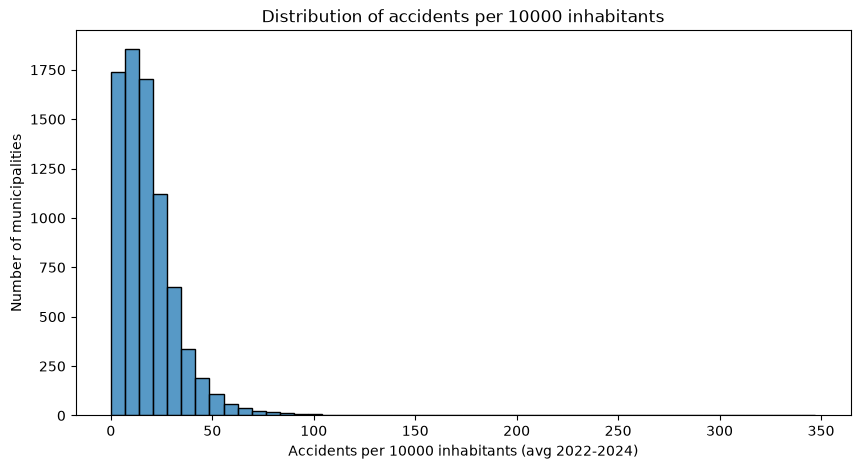

In [35]:
plt. figure(figsize=(10, 5))
sns.histplot(df_mun["accidents_per_10k"], bins=50)
plt.title("Distribution of accidents per 10000 inhabitants")
plt.xlabel("Accidents per 10000 inhabitants (avg 2022-2024)")
plt.ylabel("Number of municipalities")
plt.show()

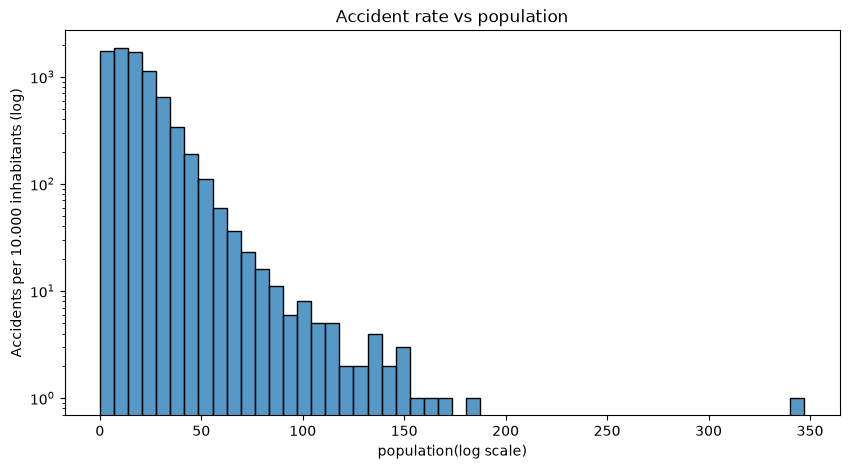

In [39]:
plt.figure(figsize=(10, 5))
sns.histplot(df_mun["accidents_per_10k"], bins=50)
plt.yscale("log")
plt.title("Accident rate vs population")
plt.xlabel("population(log scale)")
plt.ylabel("Accidents per 10.000 inhabitants (log)")
plt.show()

Finding the outliers

In [36]:
df_mun.sort_values("accidents_per_10k", ascending=False)[["municipality", "province", "population", "accidents_avg", "accidents_per_10k"]].head(10)

,municipality,province,population,accidents_avg,accidents_per_10k
153,Moncenisio,TO,48,1.666667,347.222222
1493,Brienno,CO,311,5.666667,182.207931
486,Argentera,CN,77,1.333333,173.160173
1039,Bard,AO,102,1.666667,163.398693
1316,Carrodano,SP,469,7.333333,156.361052
645,Pietraporzio,CN,67,1.000000,149.253731
856,Belforte Monferrato,AL,492,7.333333,149.051491
2704,Ponte Gardena/Waidbruck,BZ,251,3.666667,146.082337
318,Balocco,VC,211,3.000000,142.180095
4160,Forte dei Marmi,LU,6666,94.333333,141.514151


As the scatteplot shows, in small municipalities, like Moncenisio, the rate is very high and unstable, a few accidents change it a lot.

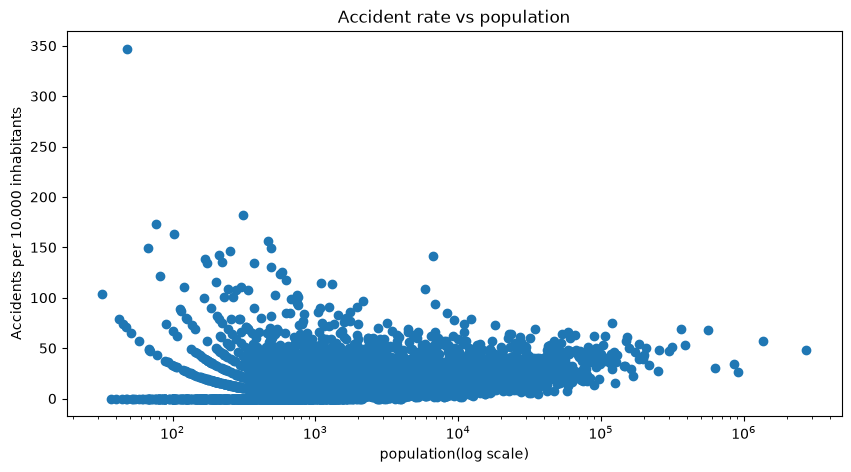

In [37]:
plt.figure(figsize=(10, 5))
plt.scatter(df_mun["population"],
            df_mun["accidents_per_10k"])
plt.xscale("log")
plt.title("Accident rate vs population")
plt.xlabel("population(log scale)")
plt.ylabel("Accidents per 10.000 inhabitants")
plt.show()

Now I want to decide which population threshold I should use

In [44]:
total = df_mun["accidents_avg"].sum()
for threshold in [1000, 5000, 10000, 20000]:
    df_big = df_mun[df_mun["population"] >= threshold]
    print(threshold, "inhabitants:", len(df_big), "municipalities,", round(df_big["accidents_avg"].sum() 
    / total * 100, 1),"% of accidents")

1000 inhabitants: 5868 municipalities, 99.0 % of accidents
5000 inhabitants: 2371 municipalities, 90.6 % of accidents
10000 inhabitants: 1202 municipalities, 81.1 % of accidents
20000 inhabitants: 510 municipalities, 68.0 % of accidents


I think that the best decision is the threshold to use is 10.000 inhabitants, which have 1202 municipalities and 81% of all accidents. I think that this threshold is safer for rates, while with 1000 it's unstable as we saw; 5000 also have some unstable rates; 20000 stable rate but I lost many accidents.
I'm keeping all municipalities in the data and dashboard, but using 10.000 for ranking, clustering and statistical tests.

## Rankings (municipalities with at least 10.000 inhabitants)

In [45]:
df_big = df_mun[df_mun["population"] >= 10000]

Total accidents

In [46]:
df_big.sort_values("accidents_avg", ascending=False)[["municipality", "province", "population", "accidents_avg"]].head(10)

,municipality,province,population,accidents_avg
4713,Roma,RM,2747290,13307.333333
1768,Milano,MI,1365698,7779.333333
1264,Genova,GE,564080,3817.000000
267,Torino,TO,853196,2940.333333
4214,Firenze,FI,361705,2499.333333
5098,Napoli,NA,909013,2420.000000
3827,Bologna,BO,390151,2074.666667
6589,Palermo,PA,628693,1889.333333
5872,Bari,BA,315831,1615.333333
6826,Catania,CT,298054,1401.333333


I found the total of accidents and more are of the biggest cities, like Rome, Milan, Turin, because they have more people.

Per inhabitant

In [47]:
df_big.sort_values("accidents_per_10k", ascending=False)[["municipality", "province", "population", "accidents_per_10k"]].head(10)

,municipality,province,population,accidents_per_10k
1267,Lavagna,GE,12367,78.434544
1853,Bergamo,BG,120389,75.062229
1199,Finale Ligure,SV,11012,73.858821
4205,Calenzano,FI,17994,73.172539
7502,Riccione,RN,34340,69.112794
4214,Firenze,FI,361705,69.098667
1264,Genova,GE,564080,67.667707
1226,Savona,SV,58581,66.460684
4203,Barberino di Mugello,FI,10939,65.819545
1157,Sanremo,IM,53059,64.268079


Per km2: the denses areas

In [49]:
df_big.sort_values("accidents_per_km2", ascending=False)[["municipality", "province", "accidents_per_km2", "pop_density"]].head(10)

,municipality,province,accidents_per_km2,pop_density
1768,Milano,MI,42.780023,7510.231241
4214,Firenze,FI,24.429572,3535.462140
1734,Cinisello Balsamo,MI,24.258619,5870.952531
267,Torino,TO,22.618158,6563.106736
1853,Bergamo,BG,22.455251,2991.551326
1739,Cormano,MI,22.354861,4637.292379
5098,Napoli,NA,20.294811,7623.242759
1808,Sesto San Giovanni,MI,19.773939,6734.992179
1741,Corsico,MI,19.008572,6465.523668
1736,Cologno Monzese,MI,17.136941,5592.593033


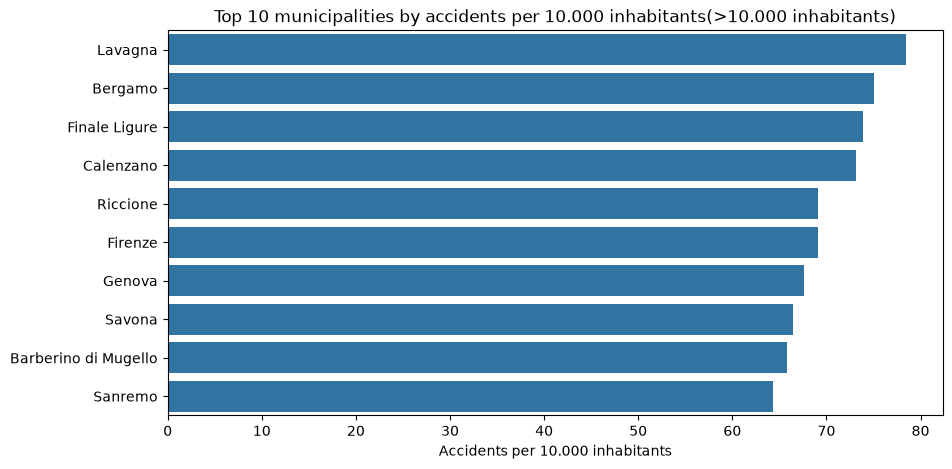

In [51]:
top_10 = df_big.sort_values("accidents_per_10k", ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(data=top_10, x="accidents_per_10k", y="municipality")
plt.title("Top 10 municipalities by accidents per 10.000 inhabitants(>10.000 inhabitants)")
plt.xlabel("Accidents per 10.000 inhabitants")
plt.ylabel("")
plt.show()

## Differences between geographic areas

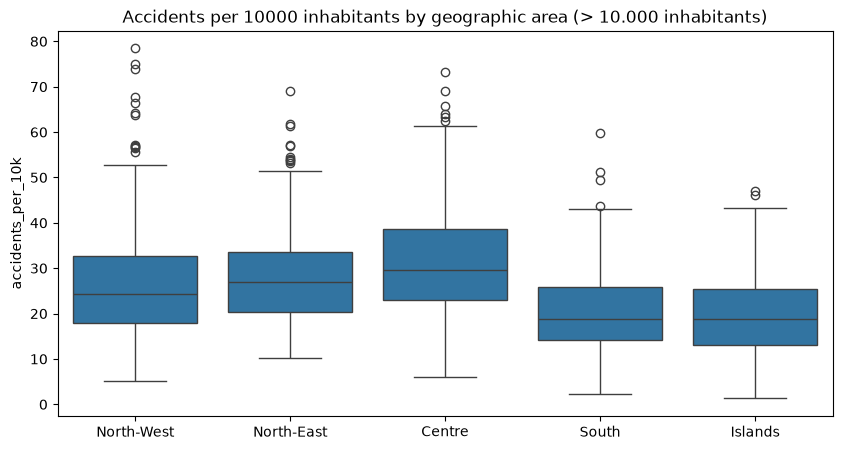

In [52]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_big, x="geographic_area", y="accidents_per_10k")
plt.title("Accidents per 10000 inhabitants by geographic area (> 10.000 inhabitants)")
plt.xlabel("")
plt.show()

In [54]:
df_big.groupby("geographic_area")["accidents_per_10k"].agg(["mean", "median", "count"])

,mean,median,count
geographic_area,,,
Centre,31.728859,29.640130,216
Islands,20.159538,18.912030,133
North-East,28.170561,26.982775,270
North-West,26.945422,24.331230,282
South,20.349848,18.805830,301


The centre and the north seem to have higher accident rate than the south and islands. I'm going to check this difference with an Anova test later. A possible explanation can be more traffic in north and center.

Correlations

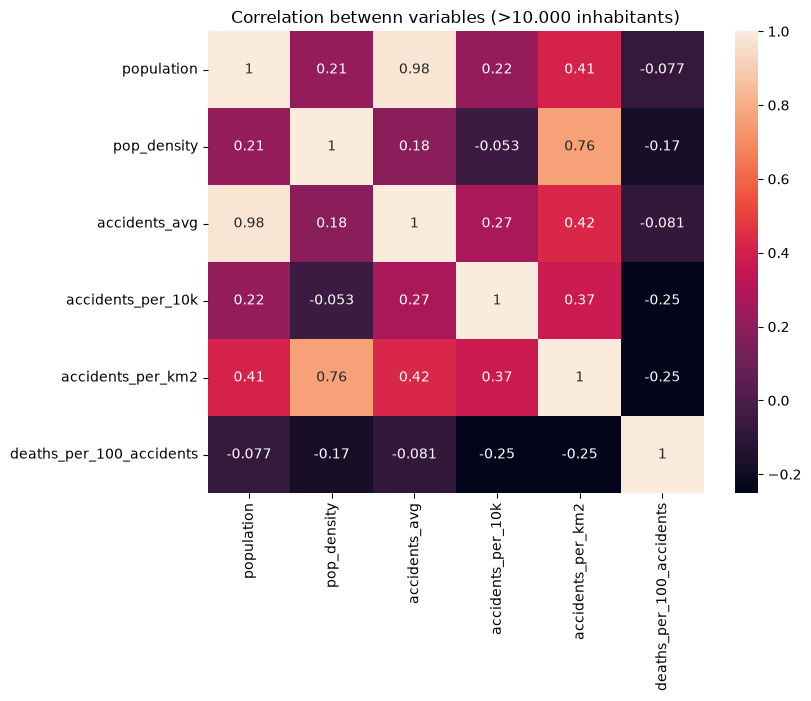

In [58]:
columns = ["population", "pop_density", "accidents_avg", "accidents_per_10k", "accidents_per_km2", "deaths_per_100_accidents"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_big[columns].corr(), annot=True)
plt.title("Correlation betwenn variables (>10.000 inhabitants)")
plt.show()

I see that the correlation between deaths_per_10_accidents and pop_density is weak(-0.17). To check this I'm going to split the municipalities into 2 groups using the median intensity.

In [59]:
median_density = df_big["pop_density"].median()
print(median_density)

498.1843361892421


In [60]:
low_density = df_big[df_big["pop_density"] < median_density]
high_density = df_big[df_big["pop_density"] >= median_density]
print("Low density - deaths per 100 accidents:", low_density["deaths_per_100_accidents"].median())
print("High density - deaths per 100 accidents:", high_density["deaths_per_100_accidents"].median())

Low density - deaths per 100 accidents: 2.272727272727273
High density - deaths per 100 accidents: 1.2757605495583904


I notice that in dense municipalities accidents are more frequest but less serious, perhaps for lower speeds, while in less dense municipalities accidents are less frequent but more serious, maybe for higher speeds.

In [61]:
df_mun.to_csv("../data/processed/municipalities_2022_2024.csv", index=False)
print("Saved")

Saved
